# ⚡ B7 – Phát Hiện Tấn Công Mạng Bằng GRU


## 1. Import Thư Viện

In [4]:
# ── Thư viện chuẩn ───────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
import warnings, os, time
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # tắt log TensorFlow

# ── TensorFlow / Keras ────────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import (
    EarlyStopping,       # dừng sớm khi val_loss không cải thiện
    ReduceLROnPlateau,   # giảm learning rate khi plateau
    ModelCheckpoint      # lưu model tốt nhất
)

# ── Scikit-learn (tiền xử lý & đánh giá) ─────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    f1_score, accuracy_score, precision_score, recall_score,
    RocCurveDisplay, ConfusionMatrixDisplay, precision_recall_curve,
    auc as sk_auc
)

# ── Style đồ thị ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
})

# ── Seed cố định cho reproducibility ─────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ Import thành công!")
print(f"   TensorFlow version : {tf.__version__}")
print(f"   Keras version      : {keras.__version__}")
gpu_list = tf.config.list_physical_devices('GPU')
print(f"   GPU available      : {'✅ ' + str(gpu_list) if gpu_list else '❌ Không có GPU – dùng CPU'}")

✅ Import thành công!
   TensorFlow version : 2.11.0
   Keras version      : 2.11.0
   GPU available      : ❌ Không có GPU – dùng CPU


## 2. Cấu Hình Tham Số

In [5]:
# ════════════════════════════════════════════════════════════════════
#  ĐỔI ĐƯỜNG DẪN NẾU CẦN
# ════════════════════════════════════════════════════════════════════


ROOT_DIR = Path.cwd()
CSV_PATH = ROOT_DIR.parent/ "Dataset" / "category_CICMAL2017_dataset.csv"

LABEL_COL = "Binary Label"  # 0 = Benign, 1 = Malware

# ── Chia dữ liệu ─────────────────────────────────────────────────────────────
TEST_SIZE = 0.20  # 20% test
VAL_SIZE = 0.10  # 10% validation (trích từ train)

# ── Huấn luyện ───────────────────────────────────────────────────────────────
BATCH_SIZE = 256  # số mẫu mỗi lần cập nhật gradient
MAX_EPOCHS = 5  # số epoch tối đa (EarlyStopping sẽ dừng sớm hơn)
PATIENCE = 7  # EarlyStopping: dừng sau 7 epoch không cải thiện

# ── Kiến trúc ────────────────────────────────────────────────────────────────
# RNN nhận input shape = (timesteps, features)
# Vì mỗi flow là 1 "điểm thời gian" → timesteps = 1, features = số đặc trưng
TIMESTEPS = 1

# ── Cột không dùng làm đặc trưng ─────────────────────────────────────────────
META_COLS = [
    "Flow ID",
    "Src IP",
    "Dst IP",
    "Timestamp",
    "Cat_Label",  # label multi-class
    "Binary Label",  # label binary
]

print("✅ Cấu hình xong!")
print(f"   File   : {CSV_PATH}")
print(
    f"   Split  : train {int((1-TEST_SIZE-VAL_SIZE)*100)}% / val {int(VAL_SIZE*100)}% / test {int(TEST_SIZE*100)}%"
)
print(
    f"   Batch  : {BATCH_SIZE}  |  Max epochs : {MAX_EPOCHS}  |  Patience : {PATIENCE}"
)

✅ Cấu hình xong!
   File   : c:\Desktop\VANN\BÁO CÁO THỰC HÀNH\CV4.1\Dataset\category_CICMAL2017_dataset.csv
   Split  : train 70% / val 10% / test 20%
   Batch  : 256  |  Max epochs : 5  |  Patience : 7


## 3. Tải & Tiền Xử Lý Dữ Liệu

In [6]:
print("Đang tải dữ liệu...")
df = pd.read_csv(CSV_PATH, low_memory=False)
df.columns = df.columns.str.strip()

print(f"Shape gốc       : {df.shape}")
print(f"Phân phối nhãn  :\n{df[LABEL_COL].value_counts().rename({0:'Benign(0)',1:'Malware(1)'})}\n")

# ── Tách đặc trưng & nhãn ────────────────────────────────────────────────────
drop_cols = [c for c in META_COLS if c in df.columns]
feat_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in drop_cols and c != LABEL_COL
]

X_raw = df[feat_cols].copy()
y     = df[LABEL_COL].values.astype(np.int32)

# ── Làm sạch: thay Inf → NaN → điền median ───────────────────────────────────
X_raw.replace([np.inf, -np.inf], np.nan, inplace=True)
X_raw.fillna(X_raw.median(), inplace=True)

# ── Loại đặc trưng phương sai = 0 (không mang thông tin) ─────────────────────
zero_var = X_raw.columns[X_raw.var() == 0].tolist()
if zero_var:
    print(f"⚠ Loại {len(zero_var)} cột phương sai=0")
    X_raw.drop(columns=zero_var, inplace=True)
    feat_cols = X_raw.columns.tolist()

N_FEATURES = X_raw.shape[1]
print(f"Số đặc trưng sau lọc : {N_FEATURES}")

# ── Chia train / test (stratified) ───────────────────────────────────────────
X_tr_val, X_te, y_tr_val, y_te = train_test_split(
    X_raw.values, y,
    test_size=TEST_SIZE, random_state=SEED, stratify=y
)

# ── Chia train / val ─────────────────────────────────────────────────────────
val_ratio = VAL_SIZE / (1 - TEST_SIZE)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_val, y_tr_val,
    test_size=val_ratio, random_state=SEED, stratify=y_tr_val
)

# ── Chuẩn hóa Z-score (fit ONLY trên train, transform cả 3 tập) ──────────────
# QUAN TRỌNG: không được fit trên val/test → tránh data leakage
scaler = StandardScaler()
X_tr  = scaler.fit_transform(X_tr)
X_val = scaler.transform(X_val)
X_te  = scaler.transform(X_te)

# ── Reshape sang 3D: (samples, timesteps, features) ──────────────────────────
# RNN yêu cầu input 3D; timesteps=1 vì mỗi flow là 1 quan sát độc lập
X_tr_rnn  = X_tr.reshape(-1, TIMESTEPS, N_FEATURES)
X_val_rnn = X_val.reshape(-1, TIMESTEPS, N_FEATURES)
X_te_rnn  = X_te.reshape(-1, TIMESTEPS, N_FEATURES)

print(f"\n✅ Dữ liệu sau reshape (samples, timesteps, features):")
print(f"   Train : {X_tr_rnn.shape}  |  labels: {np.bincount(y_tr)}")
print(f"   Val   : {X_val_rnn.shape}  |  labels: {np.bincount(y_val)}")
print(f"   Test  : {X_te_rnn.shape}  |  labels: {np.bincount(y_te)}")


Đang tải dữ liệu...
Shape gốc       : (22192, 86)
Phân phối nhãn  :
Malware(1)    17153
Benign(0)      5039
Name: Binary Label, dtype: int64

⚠ Loại 8 cột phương sai=0
Số đặc trưng sau lọc : 72

✅ Dữ liệu sau reshape (samples, timesteps, features):
   Train : (15533, 1, 72)  |  labels: [ 3527 12006]
   Val   : (2220, 1, 72)  |  labels: [ 504 1716]
   Test  : (4439, 1, 72)  |  labels: [1008 3431]


## 4. Xây Dựng Mô Hình GRU

In [7]:
# ════════════════════════════════════════════════════════════════════════════
# XÂY DỰNG MÔ HÌNH GRU
# ════════════════════════════════════════════════════════════════════════════
# GRU – Gated Recurrent Unit (Cho et al., 2014)
# Ưu điểm: chỉ 2 cổng (reset + update) → ít tham số hơn LSTM
#           → huấn luyện nhanh hơn, ít overfit hơn
#           → thường đạt kết quả tương đương LSTM
#
# Reset gate  : r(t) = σ(W_r · [h(t-1), x(t)]) → quên bao nhiêu h(t-1)?
# Update gate : z(t) = σ(W_z · [h(t-1), x(t)]) → giữ lại bao nhiêu h(t-1)?
# h(t) = (1-z)⊙h(t-1) + z⊙tanh(W·[r⊙h(t-1), x(t)])
#
# BatchNormalization sau layer đầu:
#   → chuẩn hóa activation → ổn định, hội tụ nhanh hơn

INPUT_SHAPE = (TIMESTEPS, N_FEATURES)

model = keras.Sequential([
    layers.Input(shape=INPUT_SHAPE),

    # GRU layer thứ nhất – units lớn để học đặc trưng phức tạp
    layers.GRU(
        128,
        return_sequences=True,
        kernel_regularizer=regularizers.l2(1e-4),
        dropout=0.2,
        recurrent_dropout=0.1
    ),

    # BatchNormalization: chuẩn hóa output → ổn định training
    layers.BatchNormalization(),

    # GRU layer thứ hai – thu nhỏ chiều, return_sequences=False
    layers.GRU(
        64,
        return_sequences=False,
        kernel_regularizer=regularizers.l2(1e-4),
        dropout=0.2
    ),

    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
], name="GRU_Model")

print("✅ Model GRU:")
model.summary()
print(f"\n   Tổng số tham số: {model.count_params():,}")
print(f"   Input shape    : {INPUT_SHAPE}")


✅ Model GRU:
Model: "GRU_Model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru (GRU)                   (None, 1, 128)            77568     
                                                                 
 batch_normalization (BatchN  (None, 1, 128)           512       
 ormalization)                                                   
                                                                 
 gru_1 (GRU)                 (None, 64)                37248     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                            

## 5. Định Nghĩa Callbacks

In [8]:
# ════════════════════════════════════════════════════════════════════════════
# CALLBACKS
# ════════════════════════════════════════════════════════════════════════════
# EarlyStopping : dừng huấn luyện khi val_loss không cải thiện sau PATIENCE epoch
#                 restore_best_weights=True → tự động khôi phục model tốt nhất
# ReduceLROnPlateau : khi val_loss plateau → giảm LR để thoát vùng phẳng
# ModelCheckpoint   : lưu model tốt nhất ra file .keras

def get_callbacks(model_name):
    return [
        EarlyStopping(
            monitor='val_loss',
            patience=PATIENCE,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,          # LR_new = LR_old * 0.5
            patience=4,
            min_lr=1e-6,
            verbose=1
        ),
        ModelCheckpoint(
            filepath=f'best_{model_name}.keras',
            monitor='val_loss',
            save_best_only=True,
            verbose=0
        ),
    ]

print("✅ Đã định nghĩa Callbacks!")


✅ Đã định nghĩa Callbacks!


## 6. Compile & Huấn Luyện GRU

In [9]:
# ════════════════════════════════════════════════════════════════════════════
# COMPILE & HUẤN LUYỆN GRU
# ════════════════════════════════════════════════════════════════════════════
# optimizer=Adam   : adaptive learning rate → hội tụ nhanh và ổn định
# loss=binary_crossentropy : loss function chuẩn cho phân loại nhị phân
#                            = -[y·log(p) + (1-y)·log(1-p)]
# metrics : theo dõi accuracy, AUC, Precision, Recall trong quá trình train

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

print(f"\nBắt đầu huấn luyện GRU...")
t0 = time.time()

history = model.fit(
    X_tr_rnn, y_tr,
    validation_data=(X_val_rnn, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks("gru"),
    verbose=1
)

train_time = time.time() - t0
print(f"\n  ⏱ Thời gian huấn luyện : {{train_time:.1f}}s")
print(f"  📈 Epoch tốt nhất       : {{np.argmin(history.history['val_loss']) + 1}}")
print(f"  📉 val_loss tốt nhất    : {{min(history.history['val_loss']):.4f}}")



Bắt đầu huấn luyện GRU...
Epoch 1/5
61/61 [==============================] - 7s 23ms/step - loss: 0.3142 - accuracy: 0.8802 - auc: 0.9536 - precision: 0.9698 - recall: 0.8721 - val_loss: 0.1994 - val_accuracy: 0.9752 - val_auc: 0.9828 - val_precision: 0.9770 - val_recall: 0.9913 - lr: 0.0010
Epoch 2/5
61/61 [==============================] - 1s 9ms/step - loss: 0.1231 - accuracy: 0.9728 - auc: 0.9811 - precision: 0.9771 - recall: 0.9879 - val_loss: 0.1067 - val_accuracy: 0.9833 - val_auc: 0.9864 - val_precision: 0.9844 - val_recall: 0.9942 - lr: 0.0010
Epoch 3/5
61/61 [==============================] - 1s 8ms/step - loss: 0.1018 - accuracy: 0.9777 - auc: 0.9848 - precision: 0.9817 - recall: 0.9896 - val_loss: 0.0851 - val_accuracy: 0.9851 - val_auc: 0.9884 - val_precision: 0.9861 - val_recall: 0.9948 - lr: 0.0010
Epoch 4/5
61/61 [==============================] - 1s 9ms/step - loss: 0.0958 - accuracy: 0.9795 - auc: 0.9856 - precision: 0.9816 - recall: 0.9921 - val_loss: 0.0769 - val_a

## 7. Đánh Giá Trên Tập Test

In [10]:
# ════════════════════════════════════════════════════════════════════════════
# ĐÁNH GIÁ TRÊN TẬP TEST
# ════════════════════════════════════════════════════════════════════════════
# Tập test chưa bao giờ được model thấy khi train/val
# → Kết quả phản ánh hiệu suất thực tế trên dữ liệu mới

print("Đang đánh giá trên tập test...\n")

y_prob = model.predict(X_te_rnn, batch_size=BATCH_SIZE, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)   # ngưỡng mặc định 0.5

acc   = accuracy_score(y_te, y_pred)
f1    = f1_score(y_te, y_pred, zero_division=0)
prec  = precision_score(y_te, y_pred, zero_division=0)
rec   = recall_score(y_te, y_pred, zero_division=0)
auc   = roc_auc_score(y_te, y_prob)

test_metrics = {'Accuracy': acc, 'F1': f1, 'Precision': prec,
                'Recall': rec, 'AUC': auc, 'Time(s)': train_time}

print("=" * 50)
print(f"  {'GRU'} – Kết Quả Test")
print("=" * 50)
print(f"  Accuracy  : {{acc:.4f}}")
print(f"  F1 Score  : {{f1:.4f}}")
print(f"  Precision : {{prec:.4f}}")
print(f"  Recall    : {{rec:.4f}}")
print(f"  ROC-AUC   : {{auc:.4f}}")
print(f"  Train time: {{train_time:.1f}}s")
print("=" * 50)

print("\n📋 Classification Report chi tiết:\n")
print(classification_report(y_te, y_pred,
      target_names=['Benign (0)', 'Malware (1)'], digits=4))


Đang đánh giá trên tập test...

  GRU – Kết Quả Test
  Accuracy  : {acc:.4f}
  F1 Score  : {f1:.4f}
  Precision : {prec:.4f}
  Recall    : {rec:.4f}
  ROC-AUC   : {auc:.4f}
  Train time: {train_time:.1f}s

📋 Classification Report chi tiết:

              precision    recall  f1-score   support

  Benign (0)     0.9959    0.9603    0.9778      1008
 Malware (1)     0.9885    0.9988    0.9936      3431

    accuracy                         0.9901      4439
   macro avg     0.9922    0.9796    0.9857      4439
weighted avg     0.9901    0.9901    0.9900      4439



## 8. Confusion Matrix

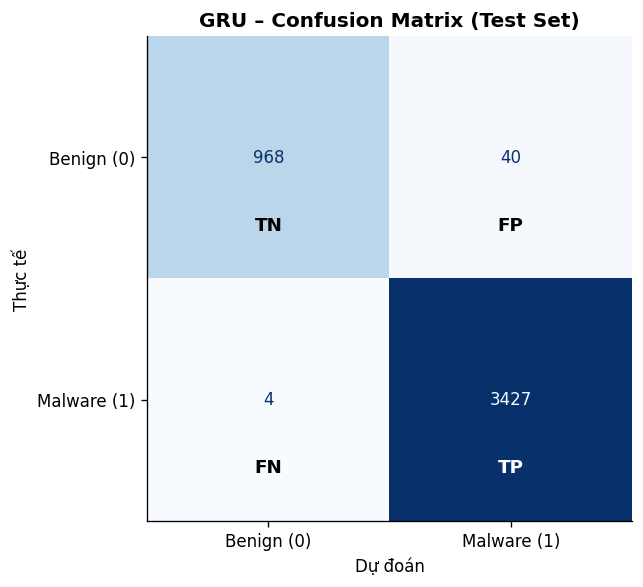

✅ Đã hiển thị confusion matrix (count)


In [11]:
# ════════════════════════════════════════════════════════════════════════════
# CONFUSION MATRIX
# ════════════════════════════════════════════════════════════════════════════
# TN: Benign → dự đoán đúng Benign     FP: Benign → dự đoán sai Malware (báo nhầm)
# FN: Malware → dự đoán sai Benign     TP: Malware → dự đoán đúng Malware
#
# Trong bảo mật: FN (bỏ lọt tấn công) nguy hiểm hơn FP (báo nhầm)
# → ta muốn Recall cao → ít FN

fig, ax = plt.subplots(figsize=(6, 5))

label_names = ['Benign (0)', 'Malware (1)']

# ── Confusion matrix (COUNT - không normalize) ─────────────────────────────
cm = confusion_matrix(y_te, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    colorbar=False,
    values_format='d'   # hiển thị số nguyên
)

# ── Thêm nhãn TN / FP / FN / TP ───────────────────────────────────────────
cell_labels = {
    (0, 0): "TN",
    (0, 1): "FP",
    (1, 0): "FN",
    (1, 1): "TP"
}

max_val = cm.max()

for (i, j), v in np.ndenumerate(cm):
    ax.text(
        j,
        i + 0.30,
        cell_labels[(i, j)],
        ha='center',
        fontsize=11,
        fontweight='bold',
        color='white' if v > max_val / 2 else 'black'
    )

# ── Label + Title ──────────────────────────────────────────────────────────
ax.set_title('GRU – Confusion Matrix (Test Set)')
ax.set_xlabel('Dự đoán')
ax.set_ylabel('Thực tế')

plt.tight_layout()
plt.show()

print("✅ Đã hiển thị confusion matrix (count)")